Inisialisasi & Koneksi ke Neo4j

In [4]:
from neo4j import GraphDatabase
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# Koneksi ke database Neo4j lokal
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "GRAF_SADA_UTS2026") # Sesuaikan password

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Koneksi berhasil terhubung ke Neo4j!")

Koneksi berhasil terhubung ke Neo4j!


In [ ]:
from neo4j import RoutingControl

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j", # Diubah ke "neo4j"
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ, # Diubah ke "neo4j"
    )
    for record in records:
        print(record["friend.name"])

# Menjalankan koneksi dan fungsi
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Koneksi dan operasi database berhasil!")
    
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Pertanyaan pendahuluan :
1. Apa nama database yang digunakan pada tutorial ini? 
    Jawaban : Pada tutorial, nama database yang digunakan adalah Neo4j, namun, nama database GRAF_SADA_UTS untuk yang saya gunakan di neo4j desktop

2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!
    Jawaban : Menggunakan perintah USE, Contoh sintaks Cypher-nya :
        USE nama_database_lain
        MATCH (n) RETURN n;

3. Apa jenis graf pertemanan yang telah dibuat di sini?
    Jawaban : Directed Graph (Graf Berarah), karena relasi penghubungnya menggunakan tanda panah (a)-[:KNOWS]->(friend), yang secara struktur mendefinisikan arah dari simpul a menuju simpul friend,

2.1: Wrangling dan EDA

1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa  

In [ ]:
import os

# Path file utama dataset
csv_file_path = r"D:\NEO4J\events.csv"

df = pd.read_csv(csv_file_path)

# Konversi kolom 'timestamp' (Unix epoch milisecond dari Retail Rocket) ke datetime
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

In [ ]:
#Definisi Rentang Waktu Periode Training (P1)
train_start = '2015-05-10 00:00:00'
train_end = '2015-07-10 23:59:59'

#Definisi Rentang Waktu Periode Testing (P2)
test_start = '2015-07-19 00:00:00'
test_end = '2015-08-03 23:59:59'

2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [ ]:
df_train = df[(df['datetime'] >= train_start) & (df['datetime'] <= train_end)]
df_test = df[(df['datetime'] >= test_start) & (df['datetime'] <= test_end)]

In [ ]:
train_output_path = r"D:\NEO4J\train_events.csv"
test_output_path = r"D:\NEO4J\test_events.csv"

df_train.to_csv(train_output_path, index=False)
df_test.to_csv(test_output_path, index=False)

3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [6]:
def get_subgraph_composition(driver):
    print("Menghitung jumlah Visitor...")
    q_visitor = "MATCH (v:Visitor) RETURN count(v) AS total" # Berfungsi untuk mencocokkan seluruh simpul berlabel Visitor lalu menghitung jumlah totalnya.
    res_v, _, _ = driver.execute_query(q_visitor, database_="neo4j")
    total_visitors = res_v[0]["total"]
    
    print("Menghitung jumlah Item...")
    q_item = "MATCH (i:Item) RETURN count(i) AS total" #Berfungsi untuk mencocokkan seluruh simpul berlabel Item lalu menghitung jumlah totalnya.
    res_i, _, _ = driver.execute_query(q_item, database_="neo4j")
    total_items = res_i[0]["total"]
    
    print("Menghitung jumlah masing-masing Relasi...")
    q_rel = """
    MATCH ()-[r]->() 
    RETURN type(r) AS rel_type, count(r) AS count
    """ 
    #Berfungsi untuk memindai seluruh relasi antar simpul, mengelompokkannya berdasarkan jenis relasi (VIEWED, ADDED_TO_CART, BOUGHT), dan menghitung total kemunculan masing-masing.
    res_r, _, _ = driver.execute_query(q_rel, database_="neo4j")
    
    print("\nKOMPOSISI SUBGRAPH")
    print(f"Total Visitor (Simpul): {total_visitors:,}")
    print(f"Total Item (Simpul): {total_items:,}")
    print("Total Relasi:")
    for row in res_r:
        print(f" - {row['rel_type']}: {row['count']:,}")

get_subgraph_composition(driver)

Menghitung jumlah Visitor...
Menghitung jumlah Item...
Menghitung jumlah masing-masing Relasi...

=== KOMPOSISI SUBGRAPH ===
Total Visitor (Simpul): 646,260
Total Item (Simpul): 169,169
Total Relasi:
 - VIEWED: 1,238,582
 - BOUGHT: 10,365
 - ADDED_TO_CART: 31,508


4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!
    
    Jawaban : user memiliki dimensi sebesar (100, 2), yang berarti bahwa struktur data terbentuk dalam tabel dua dimensi yang memuat 100 baris entitas unik pengguna (visitor_id) dan interacted_items.

In [7]:
query_vsm_user = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorid AS visitor_id, collect(DISTINCT i.itemid) AS interacted_items
LIMIT 100
"""

records, _, _ = driver.execute_query(query_vsm_user, database_="neo4j")
df_vsm_user = pd.DataFrame([dict(row) for row in records])

print("--- KARAKTERISTIK VSM USER ---")
print("Dimensi / Shape Matriks User:", df_vsm_user.shape)
display(df_vsm_user.head())

--- KARAKTERISTIK VSM USER ---
Dimensi / Shape Matriks User: (100, 2)


,visitor_id,interacted_items
0,173024,"[327485, 80874]"
1,1044116,"[327485, 310967, 298895, 221141, 53559, 263308..."
2,876377,[327485]
3,281519,"[268302, 373013, 189304, 72118]"
4,415391,[268302]


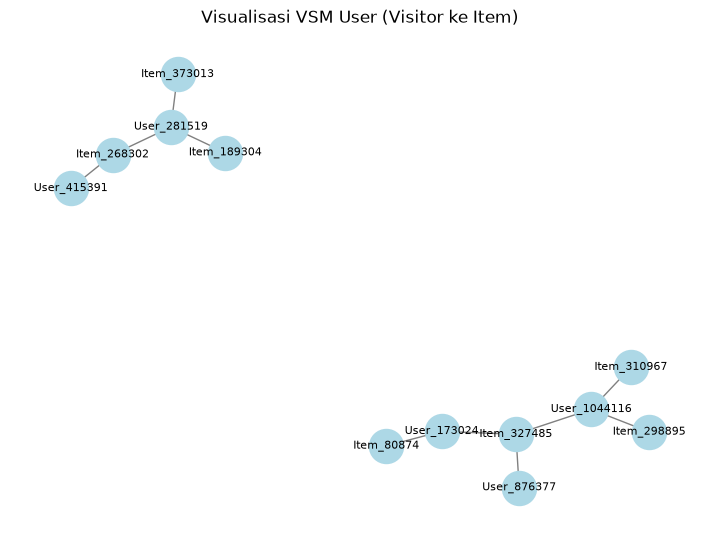

In [8]:
import networkx as nx
import matplotlib.pyplot as plt

G_user = nx.Graph()
for _, row in df_vsm_user.head(5).iterrows():
    for item in row['interacted_items'][:3]:
        G_user.add_edge(f"User_{row['visitor_id']}", f"Item_{item}")

plt.figure(figsize=(7, 5))
nx.draw(G_user, with_labels=True, node_color='lightblue', node_size=600, font_size=8, edge_color='gray')
plt.title("Visualisasi VSM User (Visitor ke Item)")
plt.show()

5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

    Jawaban     : Dua kolom utama yang terbentuk adalah item_id sebagai pengenal unik (identitas simpul item) dan interacting_visitors yang memuat himpunan ID pengunjung unik (visitorid) yang pernah berinteraksi dengan item tersebut.

In [9]:
query_vsm_item = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN i.itemid AS item_id, collect(DISTINCT v.visitorid) AS interacting_visitors
LIMIT 100
"""

records, _, _ = driver.execute_query(query_vsm_item, database_="neo4j")
df_vsm_item = pd.DataFrame([dict(row) for row in records])

print("KARAKTERISTIK VSM ITEM")
print("Dimensi / Shape Matriks Item:", df_vsm_item.shape)
display(df_vsm_item.head())

KARAKTERISTIK VSM ITEM
Dimensi / Shape Matriks Item: (100, 2)


,item_id,interacting_visitors
0,327485,"[173024, 1044116, 876377]"
1,268302,"[281519, 415391, 1169610, 194063, 798549, 8031..."
2,369924,"[953665, 977157, 842514, 979712, 8370, 369354,..."
3,133236,"[1314753, 626931, 403184, 943945, 86190, 42767..."
4,400946,"[684514, 379058, 418185, 371257, 1006835, 1493..."


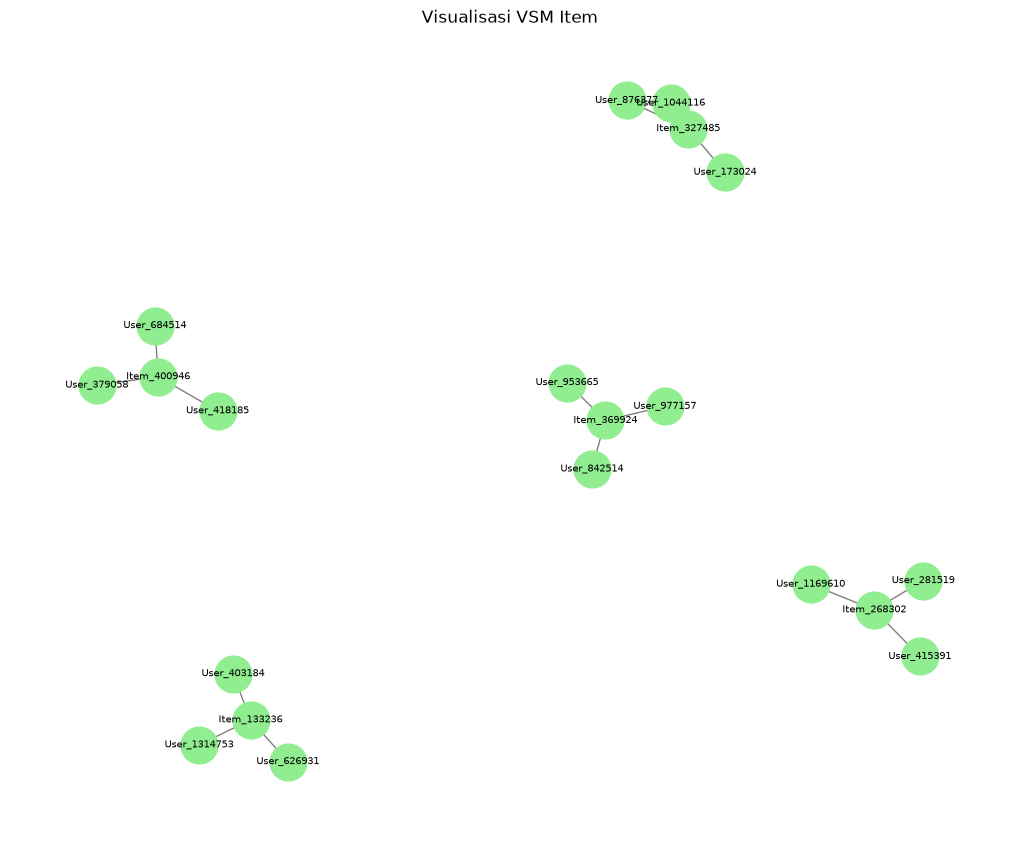

In [12]:
plt.figure(figsize=(10, 8)) # Perbesar ukuran gambar
pos = nx.spring_layout(G_item, k=0.3, iterations=50) # Atur layout agar node menyebar
nx.draw(G_item, pos, with_labels=True, node_color='lightgreen', node_size=700, font_size=7, edge_color='gray')
plt.title("Visualisasi VSM Item")
plt.show()

6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

    Jawaban : Dengan ukuran vektor interaksi item yang lebih padat dan kaya informasi dibandingkan vektor user yang sangat minim, Proyeksi Item-based jauh lebih efektif dan stabil untuk diimplementasikan pada sistem rekomendasi.

7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)! 
    Jawaban : Berdasarkan hasil analisis, item acuan 327485 memiliki 5 item mirip teratas dengan skor kemiripan sebesar 1 yang dihitung dari jumlah pengunjung unik yang sama-sama melihat item tersebut

In [16]:
target_item_id = '327485'

query_single_anchor = """
MATCH (acuan:Item {itemid: $target_id})<-[:VIEWED]-(v:Visitor)-[:VIEWED]->(target:Item)
WHERE target.itemid <> acuan.itemid
WITH acuan, target, count(DISTINCT v) AS Similarity_Score
RETURN acuan.itemid AS Item_Acuan, target.itemid AS Item_Mirip, Similarity_Score
ORDER BY Similarity_Score DESC
LIMIT 5
"""

records, _, _ = driver.execute_query(query_single_anchor, target_id=target_item_id, database_="neo4j")
df_single = pd.DataFrame([dict(row) for row in records])

print(f"5 ITEM PALING MIRIP DENGAN ACUAN ITEM: {target_item_id}")
display(df_single)

5 ITEM PALING MIRIP DENGAN ACUAN ITEM: 327485


,Item_Acuan,Item_Mirip,Similarity_Score
0,327485,310967,1
1,327485,298895,1
2,327485,221141,1
3,327485,53559,1
4,327485,80874,1


(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query
nya! 

Jawaban : Proses write-back berhasil memperkaya basis data graf dengan menyimpan relasi langsung [SIMILAR] beserta properti nilai kemiripannya

In [18]:
target_item_id = '327485'

query_write_back_single = """
MATCH (acuan:Item {itemid: $target_id})<-[:VIEWED]-(v:Visitor)-[:VIEWED]->(target:Item)
WHERE target.itemid <> acuan.itemid
WITH acuan, target, count(DISTINCT v) AS Similarity_Score
WHERE Similarity_Score >= 1
MERGE (acuan)-[r:SIMILAR]->(target)
SET r.score = Similarity_Score
RETURN acuan.itemid AS Item_Acuan, target.itemid AS Item_Mirip, r.score AS Similarity_Score
ORDER BY Similarity_Score DESC
LIMIT 5
"""

records_wb, _, _ = driver.execute_query(query_write_back_single, target_id=target_item_id, database_="neo4j")
df_wb = pd.DataFrame([dict(row) for row in records_wb])

print(f"HASIL QUERY SETELAH WRITE BACK RELASI [SIMILAR] UNTUK ITEM: {target_item_id}")
display(df_wb)

HASIL QUERY SETELAH WRITE BACK RELASI [SIMILAR] UNTUK ITEM: 327485


,Item_Acuan,Item_Mirip,Similarity_Score
0,327485,310967,1
1,327485,298895,1
2,327485,221141,1
3,327485,53559,1
4,327485,80874,1


8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

 Sebelum Similarity 
 
 Jawaban : Terdapat 3 tipe relasi utama selain relasi similarity, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT. Relasi VIEWED mendominasi secara signifikan dengan total sebanyak 1.238.582 interaksi, yang jauh melampaui jumlah interaksi ADDED_TO_CART (31.508) dan BOUGHT (10.365)

In [21]:
sebelum_similarity = """
MATCH ()-[r]->()
WHERE type(r) <> 'SIMILAR'
RETURN type(r) AS Tipe_Relasi, count(r) AS Jumlah_Total
ORDER BY Jumlah_Total DESC
"""

records_seb, _, _ = driver.execute_query(sebelum_similarity, database_="neo4j")
df_seb = pd.DataFrame([dict(row) for row in records_seb])

print("KONDISI GRAF SEBELUM PERHITUNGAN SIMILARITY")
display(df_seb)

KONDISI GRAF SEBELUM PERHITUNGAN SIMILARITY


,Tipe_Relasi,Jumlah_Total
0,VIEWED,1238582
1,ADDED_TO_CART,31508
2,BOUGHT,10365


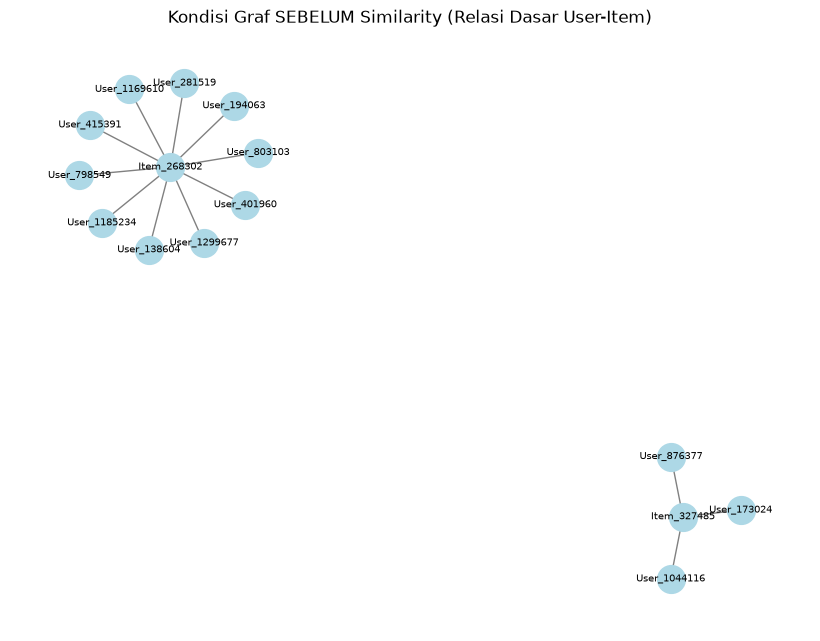

In [25]:
query_viz_before = """
MATCH (v:Visitor)-[r:VIEWED]->(i:Item)
RETURN v.visitorid AS visitor, i.itemid AS item
LIMIT 15
"""
records, _, _ = driver.execute_query(query_viz_before, database_="neo4j")

G_before = nx.Graph()
for row in records:
    G_before.add_edge(f"User_{row['visitor']}", f"Item_{row['item']}")

plt.figure(figsize=(8, 6))
nx.draw(G_before, with_labels=True, node_color='lightblue', node_size=400, font_size=7, edge_color='gray')
plt.title("Kondisi Graf SEBELUM Similarity (Relasi Dasar User-Item)")
plt.show()

Setelah Similarity

Jawaban : Setelah perhitungan similarity, data graf berhasil ditambah tipe relasi baru yakni SIMILAR sebanyak 7 entri sebagai hasil integrasi komputasi kemiripan antar-item.

In [22]:
query_sesudah = """
MATCH ()-[r]->()
RETURN type(r) AS Tipe_Relasi, count(r) AS Jumlah_Total
ORDER BY Jumlah_Total DESC
"""

records_ses, _, _ = driver.execute_query(query_sesudah, database_="neo4j")
df_ses = pd.DataFrame([dict(row) for row in records_ses])

print("KONDISI GRAF SESUDAH PERHITUNGAN SIMILARITY")
display(df_ses)

KONDISI GRAF SESUDAH PERHITUNGAN SIMILARITY


,Tipe_Relasi,Jumlah_Total
0,VIEWED,1238582
1,ADDED_TO_CART,31508
2,BOUGHT,10365
3,SIMILAR,7


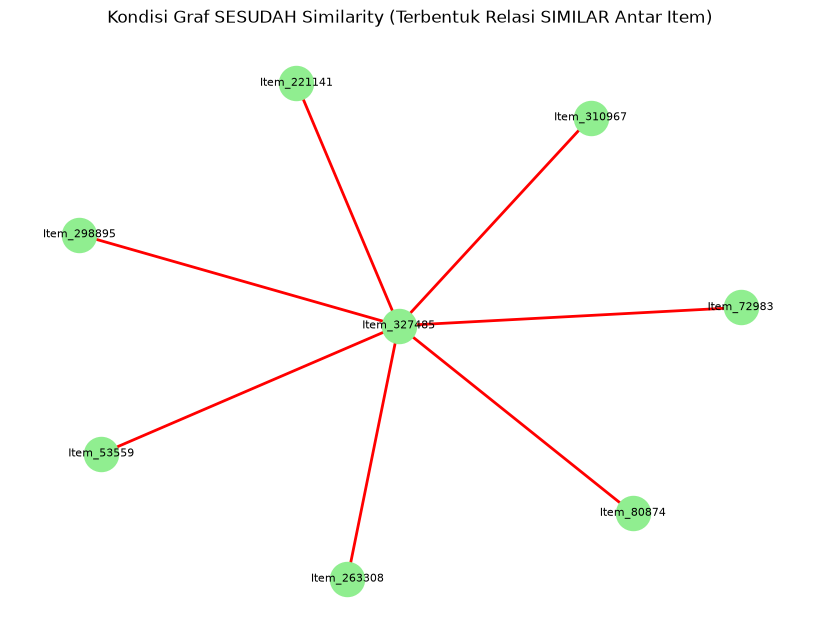

In [24]:
query_viz_after = """
MATCH (i1:Item)-[r:SIMILAR]->(i2:Item)
RETURN i1.itemid AS item1, i2.itemid AS item2
LIMIT 15
"""
records_after, _, _ = driver.execute_query(query_viz_after, database_="neo4j")

G_after = nx.Graph()
for row in records_after:
    G_after.add_edge(f"Item_{row['item1']}", f"Item_{row['item2']}", color='red')

plt.figure(figsize=(8, 6))
edges = G_after.edges()
colors = [G_after[u][v].get('color', 'black') for u, v in edges]

nx.draw(G_after, with_labels=True, node_color='lightgreen', node_size=600, font_size=8, edge_color=colors, width=2)
plt.title("Kondisi Graf SESUDAH Similarity (Terbentuk Relasi SIMILAR Antar Item)")
plt.show()

2.2 Analytics (Maks. skor: 55)

Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi) !

Jawaban :
Pemilihan simpul target user dilakukan secara pseudorandom dengan menerapkan random seed (random.seed(42) dan np.random.seed(42)), yang menghasilkan visitorid 568378 dari total sampel 500 pengunjung teratas.

In [26]:
import random
import numpy as np

# PEMILIHAN USER ACAK SECARA REPRODUCIBLE
random.seed(42)
np.random.seed(42)

# Mengambil sampel visitor dari database Neo4j
query_visitors = "MATCH (v:Visitor) RETURN v.visitorid AS visitorid LIMIT 500"
records, _, _ = driver.execute_query(query_visitors, database_="neo4j")
visitor_list = [r["visitorid"] for r in records]

target_user = random.choice(visitor_list)
print(f"User terpilih secara acak (Seed 42): {target_user}")

User terpilih secara acak (Seed 42): 568378


implementasi algoritma KNN (k5) menghasilkan 3 rekomendasi item teratas, yaitu ['40712', '30964', '294396']

In [27]:
k_neighbors = 5

query_knn_rec = """
MATCH (target:Visitor {visitorid: $target_user})-[r1]->(i:Item)<-[r2]-(neighbor:Visitor)
WHERE target <> neighbor
WITH neighbor, count(DISTINCT i) AS common_items
ORDER BY common_items DESC
LIMIT $k
MATCH (neighbor)-[:VIEWED|BOUGHT]->(rec_item:Item)
WHERE NOT (:Visitor {visitorid: $target_user})-[:VIEWED|BOUGHT]->(rec_item)
RETURN rec_item.itemid AS recommended_item, count(*) AS score
ORDER BY score DESC
LIMIT 3
"""

records_rec, _, _ = driver.execute_query(
    query_knn_rec, 
    target_user=target_user, 
    k=k_neighbors, 
    database_="neo4j"
)

recommended_items = [r["recommended_item"] for r in records_rec]
print(f"3 Item Rekomendasi teratas untuk k={k_neighbors}: {recommended_items}")

3 Item Rekomendasi teratas untuk k=5: ['40712', '30964', '294396']


2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah Hit@5 dan NDCG@5

In [ ]:
#MENGAMBIL ITEM AKTUAL (Ground Truth
query_actual = """
MATCH (v:Visitor {visitorid: $target_user})-[:BOUGHT|VIEWED]->(i:Item)
RETURN collect(DISTINCT i.itemid) AS actual_items
"""
records_actual, _, _ = driver.execute_query(query_actual, target_user=target_user, database_="neo4j")
actual_items = records_actual[0]["actual_items"] if records_actual else []

print(f"Item Aktual (Ground Truth) User: {actual_items}")

Item Aktual (Ground Truth) User: ['93502']


Evaluasi performa sistem menghasilkan nilai Hit@5 sebesar 0 dan NDCG@5 sebesar 0.0000, yang menunjukkan bahwa model rekomendasi belum berhasil memuat item aktual ('93502') ke dalam daftar rekomendasi teratas untuk target user tersebut

In [ ]:
# PERHITUNGAN (Hit@5 & NDCG@5)
def calculate_hit_at_k(recommended, actual, k=5):
    rec_k = recommended[:k]
    intersection = set(rec_k).intersection(set(actual))
    return 1 if len(intersection) > 0 else 0

def calculate_ndcg_at_k(recommended, actual, k=5):
    rec_k = recommended[:k]
    dcg = 0.0
    for i, item in enumerate(rec_k):
        if item in actual:
            dcg += 1.0 / np.log2(i + 2)
    
    idcg = 0.0
    num_relevant = min(len(actual), k)
    for i in range(num_relevant):
        idcg += 1.0 / np.log2(i + 2)
        
    return dcg / idcg if idcg > 0 else 0.0

hit_score = calculate_hit_at_k(recommended_items, actual_items, k=5)
ndcg_score = calculate_ndcg_at_k(recommended_items, actual_items, k=5)
print(f"Hit@5  : {hit_score}")
print(f"NDCG@5 : {ndcg_score:.4f}")

Hit@5  : 0
NDCG@5 : 0.0000
